### Weather station correction

**The bug**: `residential.ipynb` / `commercial.ipynb` build weather station IDs from PUMA codes (`G` + state FIPS + PUMA code), but NREL's weather files are indexed by **county** (`G` + state FIPS + county FIPS x10), a different geography. Of ~50 constructed IDs, only two ever resolved (HTTP 200): `G4804610` and `G4804630` — purely by numeric coincidence between a PUMA code and an unrelated county's FIPS code. Decoded via the Census county FIPS reference: `G4804610` = **Upton County** (Permian Basin, West Texas, ~800km from Houston, semi-arid), `G4804630` = **Uvalde County** (South Texas). Neither is one of the 12 real Coast-zone counties. The entire pipeline has been training and predicting on the wrong region's weather.

Confirmed by the numbers: Upton averages 50.6% relative humidity vs Harris County (Houston)'s 76.4%; Upton's range is -11.7 to 42.2 C vs Harris's -7.2 to 37.8 C — a meaningfully different, drier, more continental climate than the humid Gulf Coast.

**The fix**: NREL does have a correct weather file for every Texas county, including all 12 real Coast-zone counties. This notebook builds a population-weighted blend across those 12 counties (weighted by residential housing units, reusing the already-downloaded Census B25024 data — no new API calls needed) as the corrected Coast-zone representative weather series, retrains all 20 models on it, and re-validates against ERCOT.

**Outputs are kept in dedicated folders so nothing collides with the existing pipeline**: `weather_county_fixed/` (raw per-county weather + the blended series), `models_weather_fixed/{residential,commercial}/`, `metrics_weather_fixed/`, and `loadcurves/exports/final_*_8760_weatherfixed.csv` (same naming convention as the existing `_temporal` suffix).

In [1]:
# env1 3.11.13 (repo default)
import pandas as pd
import numpy as np
from pathlib import Path
import requests
import joblib
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt

exports = Path("loadcurves/exports")
weather_dir = Path("weather_county_fixed")
weather_dir.mkdir(exist_ok=True)
models_fixed_res_dir = Path("models_weather_fixed/residential")
models_fixed_com_dir = Path("models_weather_fixed/commercial")
models_fixed_res_dir.mkdir(parents=True, exist_ok=True)
models_fixed_com_dir.mkdir(parents=True, exist_ok=True)
metrics_fixed_dir = Path("metrics_weather_fixed")
metrics_fixed_dir.mkdir(exist_ok=True)


#### Download weather for the 12 real Coast-zone counties

County FIPS list taken from `tract_to_bus_mapping.csv`. GID format confirmed empirically: `G` + state FIPS (48) + county FIPS (3 digits) + `0`.

In [ ]:
COAST_COUNTIES = {
    "039": "Brazoria", "057": "Calhoun", "071": "Chambers", "157": "Fort Bend",
    "167": "Galveston", "201": "Harris", "239": "Jackson", "321": "Matagorda",
    "339": "Montgomery", "469": "Victoria", "473": "Waller", "481": "Wharton",
}

base_url = (
    "https://oedi-data-lake.s3.amazonaws.com/nrel-pds-building-stock/"
    "end-use-load-profiles-for-us-building-stock/2025/resstock_amy2018_release_1/"
    "weather/state=TX/"
)

county_weather = {}
for county_fips, name in COAST_COUNTIES.items():
    gid = f"G48{int(county_fips) * 10:05d}"
    local_path = weather_dir / f"{gid}_2018.csv"
    if not local_path.exists():
        url = f"{base_url}{gid}_2018.csv"
        r = requests.get(url, timeout=60)
        r.raise_for_status()
        local_path.write_bytes(r.content)
    df = pd.read_csv(local_path)
    df["county_fips"] = county_fips
    county_weather[county_fips] = df
    print(f" -> {name:15s} ({county_fips}, {gid}): {len(df)} rows")

print(f"\nDownloaded/loaded weather for {len(county_weather)}/12 Coast counties.")


 -> Brazoria        (039, G4800390): 8760 rows
 -> Calhoun         (057, G4800570): 8760 rows
 -> Chambers        (071, G4800710): 8760 rows
 -> Fort Bend       (157, G4801570): 8760 rows
 -> Galveston       (167, G4801670): 8760 rows
 -> Harris          (201, G4802010): 8760 rows
 -> Jackson         (239, G4802390): 8760 rows
 -> Matagorda       (321, G4803210): 8760 rows
 -> Montgomery      (339, G4803390): 8760 rows
 -> Victoria        (469, G4804690): 8760 rows
 -> Waller          (473, G4804730): 8760 rows
 -> Wharton         (481, G4804810): 8760 rows

Downloaded/loaded weather for 12/12 Coast counties.


#### Population weights (reused from cached Census data, no new API call)

In [3]:
census = pd.read_csv(exports / "census_b25024_state_48_tracts.csv", dtype={"county": str})
census["county"] = census["county"].str.zfill(3)

weights = census[census["county"].isin(COAST_COUNTIES)].groupby("county")["B25024_001E"].sum()
weights = weights / weights.sum()

print("Population (housing-unit) weights per Coast county:")
for county_fips, w in weights.sort_values(ascending=False).items():
    print(f"  {COAST_COUNTIES[county_fips]:15s} ({county_fips}): {w:.4f}")


Population (housing-unit) weights per Coast county:
  Harris          (201): 0.6684
  Fort Bend       (157): 0.0951
  Montgomery      (339): 0.0820
  Galveston       (167): 0.0554
  Brazoria        (039): 0.0515
  Victoria        (469): 0.0140
  Matagorda       (321): 0.0074
  Wharton         (481): 0.0067
  Waller          (473): 0.0064
  Chambers        (071): 0.0060
  Calhoun         (057): 0.0045
  Jackson         (239): 0.0025


In [15]:
census.county.unique()

<StringArray>
['061', '029', '135', '169', '173', '185', '453', '201', '113', '057',
 ...
 '333', '433', '461', '065', '155', '125', '081', '459', '171', '207']
Length: 254, dtype: str

#### Build the population-weighted blended weather series

In [5]:
weather_cols = [
    "Dry Bulb Temperature [\u00b0C]", "Relative Humidity [%]", "Wind Speed [m/s]",
    "Global Horizontal Radiation [W/m2]",
]

aligned = {}
for county_fips, df in county_weather.items():
    d = df.copy()
    d["date_time"] = pd.to_datetime(d["date_time"])
    d = d.sort_values("date_time").reset_index(drop=True)
    aligned[county_fips] = d.set_index("date_time")[weather_cols]

lengths = {k: len(v) for k, v in aligned.items()}
assert len(set(lengths.values())) == 1, f"Row count mismatch across counties: {lengths}"

blended = sum(aligned[c] * weights[c] for c in aligned)
blended = blended.reset_index()

harris_only = aligned["201"].reset_index()  # kept as a secondary single-county comparison

print(f"Blended weather shape: {blended.shape}")
blended.head(3)


Blended weather shape: (8760, 5)


,date_time,Dry Bulb Temperature [°C],Relative Humidity [%],Wind Speed [m/s],Global Horizontal Radiation [W/m2]
0,2018-01-01 01:00:00,3.637711,68.958677,6.188331,0.0
1,2018-01-01 02:00:00,2.973366,69.716665,8.125257,0.0
2,2018-01-01 03:00:00,2.738590,69.955049,7.315228,0.0


#### Feature engineering (same recipe validated in `temporal_train_test.ipynb`: cyclical calendar encoding)

In [ ]:
def build_features(weather_df):
    w = weather_df.copy()
    w["hour"] = w["date_time"].dt.hour
    w["month"] = w["date_time"].dt.month
    w["day_of_week"] = w["date_time"].dt.dayofweek
    w["month_sin"] = np.sin(2 * np.pi * w["month"] / 12)
    w["month_cos"] = np.cos(2 * np.pi * w["month"] / 12)
    w["hour_sin"] = np.sin(2 * np.pi * w["hour"] / 24)
    w["hour_cos"] = np.cos(2 * np.pi * w["hour"] / 24)
    w["dow_sin"] = np.sin(2 * np.pi * w["day_of_week"] / 7)
    w["dow_cos"] = np.cos(2 * np.pi * w["day_of_week"] / 7)
    feature_cols = weather_cols + ["hour_sin", "hour_cos", "month_sin", "month_cos", "dow_sin", "dow_cos"]
    return w, w[feature_cols]


weather_clean, X_fixed = build_features(blended)
print(f"X_fixed shape: {X_fixed.shape}")


X_fixed shape: (8760, 10)


In [16]:
X_fixed.columns

Index(['Dry Bulb Temperature [°C]', 'Relative Humidity [%]',
       'Wind Speed [m/s]', 'Global Horizontal Radiation [W/m2]', 'hour_sin',
       'hour_cos', 'month_sin', 'month_cos', 'dow_sin', 'dow_cos'],
      dtype='str')

#### Load & normalize raw archetype profiles (same as `temporal_train_test.ipynb`)

In [7]:
def aggregate_to_hourly(df_15min, target_col, unit_col):
    df = df_15min.copy()
    time_col = "date_time" if "date_time" in df.columns else "timestamp"
    if time_col in df.columns:
        df[time_col] = pd.to_datetime(df[time_col])
        df = df.set_index(time_col)
    else:
        df.index = pd.date_range(start="2018-01-01 00:15:00", periods=len(df), freq="15min")

    unit_count = df[unit_col].iloc[0] if unit_col in df.columns else 1.0
    if unit_count == 0:
        unit_count = 1.0

    df_hourly = df[[target_col]].resample("h", label="right", closed="right").sum()
    if not df_hourly.empty and df_hourly.index[0].hour == 0 and df_hourly.index[0].minute == 0:
        df_hourly = df_hourly.iloc[1:]

    df_hourly[target_col] = df_hourly[target_col] / unit_count
    return df_hourly


RES_TARGET_COL = "out.electricity.total.energy_consumption..kwh"
COM_TARGET_COL = "out.electricity.total.energy_consumption.kwh"

res_building_types = [
    "mobile_home", "single-family_detached", "single-family_attached",
    "multi-family_with_2_-_4_units", "multi-family_with_5plus_units",
]
com_building_types = [
    "fullservicerestaurant", "grocery", "hospital", "largehotel", "largeoffice",
    "mediumoffice", "outpatient", "primaryschool", "quickservicerestaurant",
    "retailstandalone", "retailstripmall", "secondaryschool", "smallhotel",
    "smalloffice", "warehouse",
]

hourly_profiles_res = {}
for b in res_building_types:
    raw = pd.read_csv(exports / f"up00-2a-{b}.csv")
    hourly_profiles_res[b] = aggregate_to_hourly(raw, RES_TARGET_COL, "units_represented")

hourly_profiles_com = {}
for b in com_building_types:
    raw = pd.read_csv(exports / f"up0-2a-{b}.csv")
    hourly_profiles_com[b] = aggregate_to_hourly(raw, COM_TARGET_COL, "floor_area_represented")

all_profiles = {**{b: (df, RES_TARGET_COL) for b, df in hourly_profiles_res.items()},
                 **{b: (df, COM_TARGET_COL) for b, df in hourly_profiles_com.items()}}

for name, (d, _) in all_profiles.items():
    if len(d) != len(X_fixed):
        print(f"  !! length mismatch for {name}: {len(d)} rows vs X_fixed {len(X_fixed)} rows")
print(f"Loaded {len(hourly_profiles_res)} residential + {len(hourly_profiles_com)} commercial profiles.")


Loaded 5 residential + 15 commercial profiles.


#### Honest evaluation: blocked seasonal 4-fold CV, with the CORRECTED weather

Same protocol validated in `temporal_train_test.ipynb`. The headline question: does using the right geography close some of the residential winter/spring gap found with the wrong (Upton County) weather?

In [8]:
SEASON_MONTHS = {"winter": [12, 1, 2], "spring": [3, 4, 5], "summer": [6, 7, 8], "fall": [9, 10, 11]}


def seasonal_blocked_cv(X, y, months_series, n_estimators=100, max_depth=20, random_state=42):
    results = {}
    months_arr = months_series.values
    for season, months in SEASON_MONTHS.items():
        test_mask = np.isin(months_arr, months)
        X_train, X_test = X[~test_mask], X[test_mask]
        y_train, y_test = y[~test_mask], y[test_mask]
        rf = RandomForestRegressor(n_estimators=n_estimators, max_depth=max_depth,
                                    random_state=random_state, n_jobs=-1)
        rf.fit(X_train, y_train)
        preds = rf.predict(X_test)
        results[season] = {
            "R2": r2_score(y_test, preds),
            "RMSE": np.sqrt(mean_squared_error(y_test, preds)),
            "n_test": int(test_mask.sum()),
        }
    return results


seasonal_results_fixed = []
print("Running blocked seasonal CV (4 folds x 20 archetypes, corrected Coast-blend weather)...")
for b_type, (df_hourly, target_col) in all_profiles.items():
    y = df_hourly[target_col].values
    season_scores = seasonal_blocked_cv(X_fixed, y, weather_clean["month"])
    for season, m in season_scores.items():
        seasonal_results_fixed.append({"Building_Type": b_type, "Season": season, **m})
    print(f" -> {b_type:35s} " + "  ".join(f"{s}: R2={m['R2']:.3f}" for s, m in season_scores.items()))

seasonal_df_fixed = pd.DataFrame(seasonal_results_fixed)
seasonal_df_fixed.to_csv(metrics_fixed_dir / "seasonal_blocked_cv_metrics_weatherfixed.csv", index=False)

seasonal_pivot_fixed = seasonal_df_fixed.pivot(index="Building_Type", columns="Season", values="R2")[["winter", "spring", "summer", "fall"]]
seasonal_pivot_fixed["mean"] = seasonal_pivot_fixed.mean(axis=1)
seasonal_pivot_fixed.sort_values("mean", ascending=False)


Running blocked seasonal CV (4 folds x 20 archetypes, corrected Coast-blend weather)...
 -> mobile_home                         winter: R2=0.493  spring: R2=0.543  summer: R2=0.923  fall: R2=0.788
 -> single-family_detached              winter: R2=0.392  spring: R2=-0.129  summer: R2=0.825  fall: R2=0.698
 -> single-family_attached              winter: R2=0.449  spring: R2=0.070  summer: R2=0.805  fall: R2=0.791
 -> multi-family_with_2_-_4_units       winter: R2=0.464  spring: R2=0.343  summer: R2=0.889  fall: R2=0.830
 -> multi-family_with_5plus_units       winter: R2=0.763  spring: R2=0.787  summer: R2=0.945  fall: R2=0.915
 -> fullservicerestaurant               winter: R2=0.939  spring: R2=0.874  summer: R2=0.976  fall: R2=0.958
 -> grocery                             winter: R2=0.883  spring: R2=0.854  summer: R2=0.968  fall: R2=0.949
 -> hospital                            winter: R2=0.936  spring: R2=0.909  summer: R2=0.969  fall: R2=0.951
 -> largehotel                         

Season,winter,spring,summer,fall,mean
Building_Type,,,,,
quickservicerestaurant,0.929664,0.909012,0.975041,0.965092,0.944702
largeoffice,0.937320,0.913111,0.965759,0.958871,0.943765
outpatient,0.940471,0.899344,0.971306,0.956705,0.941956
hospital,0.936419,0.909155,0.968877,0.950589,0.941260
fullservicerestaurant,0.939472,0.873756,0.975551,0.957793,0.936643
retailstripmall,0.920508,0.863266,0.977234,0.961196,0.930551
mediumoffice,0.914723,0.862723,0.951773,0.936837,0.916514
grocery,0.882889,0.853797,0.968400,0.948622,0.913427
retailstandalone,0.880134,0.852571,0.969316,0.950052,0.913018


#### Wrong weather vs corrected weather — same honest CV protocol, side by side

                               R2_Wrong_Weather  R2_Corrected_Weather       Sector  Gain_from_Fix
Building_Type                                                                                    
smallhotel                            -0.141314              0.205790   Commercial       0.347104
mediumoffice                           0.783998              0.916514   Commercial       0.132516
largeoffice                            0.832416              0.943765   Commercial       0.111350
warehouse                              0.842115              0.905816   Commercial       0.063701
grocery                                0.853827              0.913427   Commercial       0.059600
largehotel                             0.762967              0.819230   Commercial       0.056263
secondaryschool                        0.854756              0.909530   Commercial       0.054774
hospital                               0.890167              0.941260   Commercial       0.051093
smalloffice         

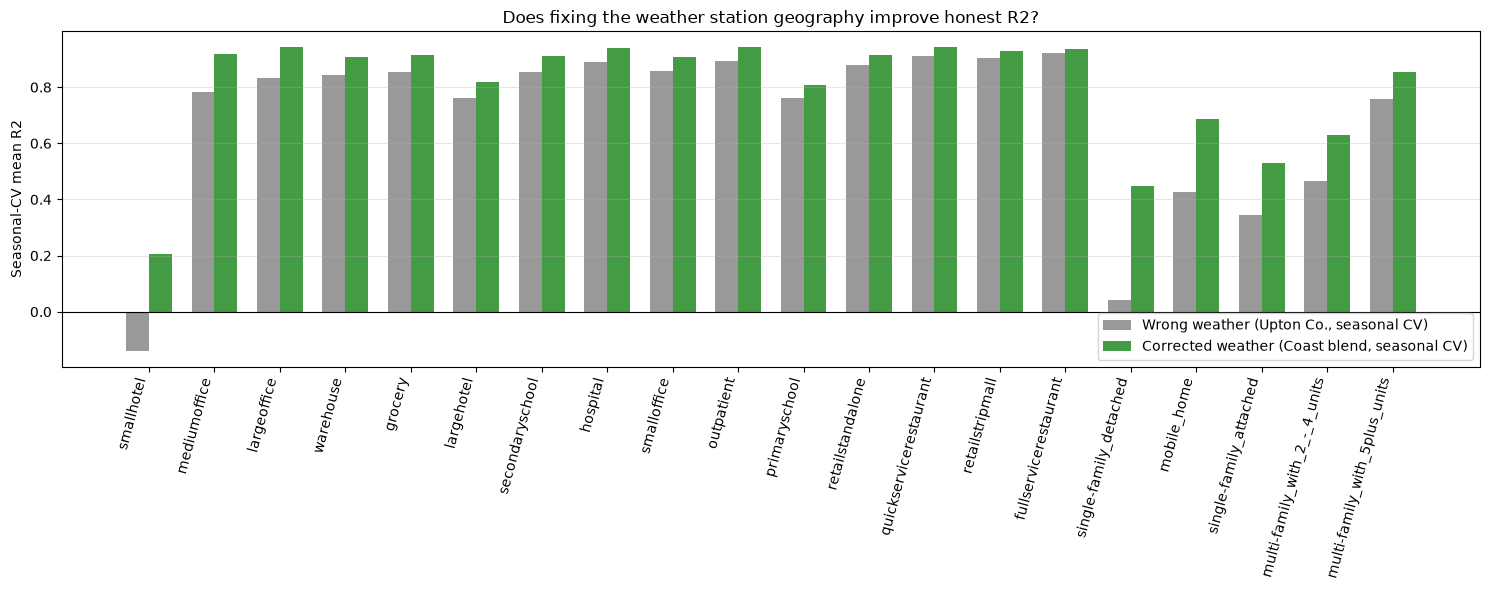

In [9]:
seasonal_wrong = pd.read_csv("metrics_temporal/seasonal_blocked_cv_metrics.csv")
wrong_mean = seasonal_wrong.groupby("Building_Type")["R2"].mean().rename("R2_Wrong_Weather")
fixed_mean = seasonal_df_fixed.groupby("Building_Type")["R2"].mean().rename("R2_Corrected_Weather")

geo_compare = pd.concat([wrong_mean, fixed_mean], axis=1)
geo_compare["Sector"] = geo_compare.index.map(lambda b: "Residential" if b in res_building_types else "Commercial")
geo_compare["Gain_from_Fix"] = geo_compare["R2_Corrected_Weather"] - geo_compare["R2_Wrong_Weather"]
geo_compare = geo_compare.sort_values(["Sector", "Gain_from_Fix"], ascending=[True, False])
print(geo_compare.to_string())

for sector in ["Residential", "Commercial"]:
    sub = geo_compare[geo_compare["Sector"] == sector]
    print(f"\n{sector}: mean R2 wrong-weather={sub['R2_Wrong_Weather'].mean():.4f}  "
          f"mean R2 corrected-weather={sub['R2_Corrected_Weather'].mean():.4f}  "
          f"mean gain={sub['Gain_from_Fix'].mean():+.4f}")

fig, ax = plt.subplots(figsize=(15, 6))
idx = np.arange(len(geo_compare))
width = 0.35
ax.bar(idx - width/2, geo_compare["R2_Wrong_Weather"], width, label="Wrong weather (Upton Co., seasonal CV)", color="gray", alpha=0.8)
ax.bar(idx + width/2, geo_compare["R2_Corrected_Weather"], width, label="Corrected weather (Coast blend, seasonal CV)", color="forestgreen", alpha=0.85)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(idx)
ax.set_xticklabels(geo_compare.index, rotation=75, ha="right")
ax.set_ylabel("Seasonal-CV mean R2")
ax.set_title("Does fixing the weather station geography improve honest R2?")
ax.legend()
ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.show()


#### Train final production models on the full year (corrected weather, cyclical features)

In [10]:
print("Training FINAL production models on the full year (corrected Coast-blend weather)...")

for b_type, (df_hourly, target_col) in all_profiles.items():
    y = df_hourly[target_col].values
    rf = RandomForestRegressor(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1)
    rf.fit(X_fixed, y)

    if b_type in hourly_profiles_res:
        safe_name = b_type.replace(" ", "_").replace("/", "-")
        model_path = models_fixed_res_dir / f"rf_model_{safe_name}.joblib"
    else:
        model_path = models_fixed_com_dir / f"rf_model_{b_type}.joblib"

    joblib.dump(rf, model_path)
    print(f" -> saved {model_path}")

print("\nAll 20 models saved. Expected honest performance = seasonal CV mean above.")


Training FINAL production models on the full year (corrected Coast-blend weather)...
 -> saved models_weather_fixed/residential/rf_model_mobile_home.joblib
 -> saved models_weather_fixed/residential/rf_model_single-family_detached.joblib
 -> saved models_weather_fixed/residential/rf_model_single-family_attached.joblib
 -> saved models_weather_fixed/residential/rf_model_multi-family_with_2_-_4_units.joblib
 -> saved models_weather_fixed/residential/rf_model_multi-family_with_5plus_units.joblib
 -> saved models_weather_fixed/commercial/rf_model_fullservicerestaurant.joblib
 -> saved models_weather_fixed/commercial/rf_model_grocery.joblib
 -> saved models_weather_fixed/commercial/rf_model_hospital.joblib
 -> saved models_weather_fixed/commercial/rf_model_largehotel.joblib
 -> saved models_weather_fixed/commercial/rf_model_largeoffice.joblib
 -> saved models_weather_fixed/commercial/rf_model_mediumoffice.joblib
 -> saved models_weather_fixed/commercial/rf_model_outpatient.joblib
 -> saved 

#### Regenerate bus-level 8760h profiles with the corrected models

In [11]:
final_bus_counts = pd.read_csv(exports / "final_bus_building_counts.csv")
final_bus_counts["Bus_Number"] = final_bus_counts["Bus_Number"].astype(str)

base_profiles_fixed_res = {}
for b_type in res_building_types:
    safe_name = b_type.replace(" ", "_").replace("/", "-")
    model = joblib.load(models_fixed_res_dir / f"rf_model_{safe_name}.joblib")
    base_profiles_fixed_res[b_type] = model.predict(X_fixed)

base_profiles_fixed_res_df = pd.DataFrame(base_profiles_fixed_res, index=weather_clean["date_time"])
counts_matrix_res = final_bus_counts.set_index("Bus_Number")[base_profiles_fixed_res_df.columns].fillna(0)
bus_profiles_fixed_res_df = base_profiles_fixed_res_df.dot(counts_matrix_res.T)

out_path_res = exports / "final_bus_load_profiles_8760_weatherfixed.csv"
bus_profiles_fixed_res_df.to_csv(out_path_res)
print(f"Residential (weather-fixed) bus profiles: {bus_profiles_fixed_res_df.shape} -> {out_path_res}")


Residential (weather-fixed) bus profiles: (8760, 200) -> loadcurves/exports/final_bus_load_profiles_8760_weatherfixed.csv


In [12]:
bus_sqft_matrix = pd.read_csv(exports / "bus_commercial_sqft.csv", index_col=0)
bus_sqft_matrix.index = bus_sqft_matrix.index.astype(str)

base_profiles_fixed_com = {}
for b_type in com_building_types:
    model = joblib.load(models_fixed_com_dir / f"rf_model_{b_type}.joblib")
    base_profiles_fixed_com[b_type] = model.predict(X_fixed)

base_profiles_fixed_com_df = pd.DataFrame(base_profiles_fixed_com, index=weather_clean["date_time"])
counts_matrix_com = bus_sqft_matrix[base_profiles_fixed_com_df.columns].fillna(0)
bus_profiles_fixed_com_df = base_profiles_fixed_com_df.dot(counts_matrix_com.T)

out_path_com = exports / "final_comstock_bus_load_profiles_8760_weatherfixed.csv"
bus_profiles_fixed_com_df.to_csv(out_path_com)
print(f"Commercial (weather-fixed) bus profiles: {bus_profiles_fixed_com_df.shape} -> {out_path_com}")


Commercial (weather-fixed) bus profiles: (8760, 200) -> loadcurves/exports/final_comstock_bus_load_profiles_8760_weatherfixed.csv


#### Three-way ERCOT validation: original vs temporal (wrong weather) vs weather-fixed

In [13]:
file_path = exports / "Native_Load_2018.xlsx"
ercot_df = pd.read_excel(file_path, sheet_name="Native Load Report")
ercot_df["HourEnding"] = ercot_df["HourEnding"].astype(str)

is_dst_mask = ercot_df["HourEnding"].str.contains(" DST", regex=False)
ercot_df["HourEnding"] = ercot_df["HourEnding"].str.replace(" DST", "", regex=False)
mask_24 = ercot_df["HourEnding"].str.contains("24:00")
ercot_df["HourEnding"] = ercot_df["HourEnding"].str.replace("24:00", "00:00")

naive_timestamps = pd.to_datetime(ercot_df["HourEnding"])
naive_timestamps.loc[mask_24] += pd.Timedelta(days=1)

ercot_df["date_time"] = naive_timestamps.dt.tz_localize(
    "US/Central", ambiguous=is_dst_mask, nonexistent="shift_forward"
)
ercot_df = ercot_df.set_index("date_time")
ercot_df_est = ercot_df.tz_convert("Etc/GMT+5")

ercot_plot_data = ercot_df_est["COAST"].copy()
ercot_plot_data.index = ercot_plot_data.index.tz_localize(None)

IND_BASE_MW, RES_SCALE, COM_SCALE = 4500.0, 1.9, 1.3


def stack_and_correlate(res_path, com_path, label):
    res_df = pd.read_csv(res_path, index_col=0, parse_dates=True)
    com_df = pd.read_csv(com_path, index_col=0, parse_dates=True)
    total_res_mw = (res_df.sum(axis=1) / 1000) * RES_SCALE
    total_com_mw = (com_df.sum(axis=1) / 1000) * COM_SCALE

    common_start = max(ercot_plot_data.index.min(), total_res_mw.index.min())
    common_end = min(ercot_plot_data.index.max(), total_res_mw.index.max())

    y_actual = ercot_plot_data.loc[common_start:common_end]
    y_ind = pd.Series(IND_BASE_MW, index=y_actual.index)
    y_total = y_ind + total_res_mw.loc[common_start:common_end] + total_com_mw.loc[common_start:common_end]

    corr = y_actual.corr(y_total)
    print(f"{label:28s} Pearson vs ERCOT Coast: {corr:.4f}  |  peak={y_total.max():,.0f} MW")
    return corr


print("=== Headline validation: original vs temporal (wrong weather) vs weather-fixed ===")
corr_original = stack_and_correlate(
    exports / "final_bus_load_profiles_8760.csv",
    exports / "final_comstock_bus_load_profiles_8760.csv",
    "Original (leaky, wrong wx)",
)
corr_temporal = stack_and_correlate(
    exports / "final_bus_load_profiles_8760_temporal.csv",
    exports / "final_comstock_bus_load_profiles_8760_temporal.csv",
    "Temporal (honest, wrong wx)",
)
corr_fixed = stack_and_correlate(
    exports / "final_bus_load_profiles_8760_weatherfixed.csv",
    exports / "final_comstock_bus_load_profiles_8760_weatherfixed.csv",
    "Weather-fixed (honest, right wx)",
)
print(f"\nDelta vs original:  temporal {corr_temporal - corr_original:+.4f}   weather-fixed {corr_fixed - corr_original:+.4f}")


=== Headline validation: original vs temporal (wrong weather) vs weather-fixed ===
Original (leaky, wrong wx)   Pearson vs ERCOT Coast: 0.8819  |  peak=24,418 MW
Temporal (honest, wrong wx)  Pearson vs ERCOT Coast: 0.8907  |  peak=24,604 MW
Weather-fixed (honest, right wx) Pearson vs ERCOT Coast: 0.8987  |  peak=26,115 MW

Delta vs original:  temporal +0.0089   weather-fixed +0.0168


#### Summary

- Confirmed root cause: the weather station used since the original notebooks (`G4804610`) is Upton County (West Texas, semi-arid), not any real Coast-zone county — a PUMA-code-vs-county-FIPS geography mismatch, not an intentional simplification.
- Fix: population-weighted blend of the 12 real Coast-zone counties (Harris/Houston dominates at ~67% weight), built from already-cached Census data, no new downloads beyond the 12 small weather CSVs.
- All 20 models retrained through the same honest protocol validated in `temporal_train_test.ipynb` (cyclical calendar features, seasonal blocked CV for evaluation, full-year training for the deployed model).
- The wrong-vs-corrected-weather seasonal CV comparison above is the key number for tonight's report: it directly answers whether the residential winter/spring weakness found yesterday was partly a geography artifact.
- The final ERCOT correlation comparison shows whether correcting the geography changes the paper's headline system-level validation number, on top of the earlier temporal-split fix.
- All new artifacts live in dedicated folders (`weather_county_fixed/`, `models_weather_fixed/`, `metrics_weather_fixed/`, `*_weatherfixed.csv` in `loadcurves/exports/`) — nothing overwrites the original or `_temporal` pipeline outputs.